In [1]:
from matplotlib import pyplot as plt
import pandas as pd
import seaborn as sns

sns.set()

In [2]:
train = pd.read_csv("./kaggle_data/train.csv", index_col=0)
metadata = pd.read_csv("./kaggle_data/metadata.csv", index_col=0)
print(metadata.shape)
print(train.shape)

(251, 31)
(266266, 4)


In [3]:
metadata.columns

Index(['building_id', 'site_id', 'site_id_kaggle', 'primaryspaceusage',
       'sub_primaryspaceusage', 'sqm', 'sqft', 'lat', 'lng', 'timezone',
       'electricity', 'hotwater', 'chilledwater', 'steam', 'water',
       'irrigation', 'solar', 'gas', 'industry', 'subindustry', 'heatingtype',
       'yearbuilt', 'date_opened', 'numberoffloors', 'occupants',
       'energystarscore', 'eui', 'site_eui', 'source_eui', 'leed_level',
       'rating'],
      dtype='object')

In [4]:
metadata.head()

,building_id,site_id,site_id_kaggle,primaryspaceusage,sub_primaryspaceusage,sqm,sqft,lat,lng,timezone,...,yearbuilt,date_opened,numberoffloors,occupants,energystarscore,eui,site_eui,source_eui,leed_level,rating
136,432,Trapano,143.0,Education,College Classroom,4703.0,50623.0,51.51879,-0.134556,Europe/London,...,NaN,NaN,5.0,NaN,NaN,NaN,NaN,NaN,NaN,G
137,416,Trapano,143.0,Education,College Classroom,499.3,5374.0,51.51879,-0.134556,Europe/London,...,NaN,NaN,4.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
138,436,Trapano,143.0,Education,College Classroom,9061.0,97532.0,51.51879,-0.134556,Europe/London,...,2005.0,NaN,10.0,NaN,NaN,NaN,NaN,NaN,NaN,F
139,441,Trapano,143.0,Education,College Laboratory,7579.0,81580.0,51.51879,-0.134556,Europe/London,...,1913.0,NaN,5.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
140,442,Trapano,143.0,Education,College Laboratory,5295.0,56995.0,51.51879,-0.134556,Europe/London,...,1953.0,NaN,6.0,NaN,NaN,NaN,NaN,NaN,NaN,G


In [5]:
for c in metadata.columns:
    print(c, len(metadata[c].unique()))
    if len(metadata[c].unique())<5:
        print("\t\t", metadata[c].unique())

building_id 251
site_id 5
site_id_kaggle 4
		 [143.  52.  nan  13.]
primaryspaceusage 12
sub_primaryspaceusage 26
sqm 245
sqft 245
lat 5
lng 5
timezone 2
		 ['Europe/London' 'Europe/Dublin']
electricity 2
		 ['Yes' nan]
hotwater 2
		 [nan 'Yes']
chilledwater 1
		 [nan]
steam 1
		 [nan]
water 2
		 [nan 'Yes']
irrigation 1
		 [nan]
solar 1
		 [nan]
gas 2
		 [nan 'Yes']
industry 4
		 ['Education' 'Government' 'Hospitality' 'Healthcare']
subindustry 12
heatingtype 13
yearbuilt 41
date_opened 1
		 [nan]
numberoffloors 15
occupants 101
energystarscore 1
		 [nan]
eui 1
		 [nan]
site_eui 1
		 [nan]
source_eui 1
		 [nan]
leed_level 1
		 [nan]
rating 10


## Let's clean a bit

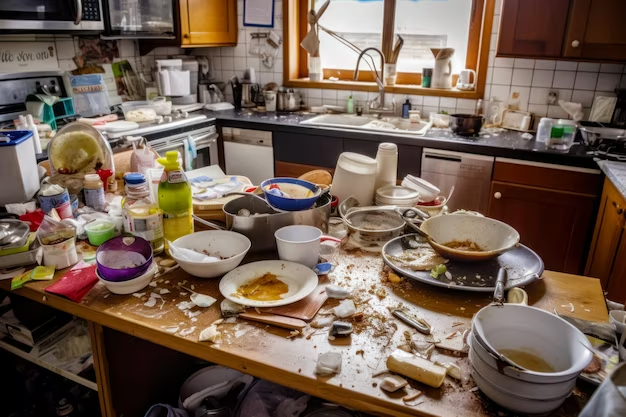

our data ^^

### Dropping meaningless columns

In [6]:
for c in metadata.columns:
    if len(metadata[c].unique())==1:
        print("Useless:", c)

Useless: chilledwater
Useless: steam
Useless: irrigation
Useless: solar
Useless: date_opened
Useless: energystarscore
Useless: eui
Useless: site_eui
Useless: source_eui
Useless: leed_level


In [7]:
# dropping a column

metadata = metadata.drop(columns=["site_id_kaggle"])

Are there any other columns that you deem meaningless? Write your code here:

In [8]:
### your code
for c in metadata.columns:
    if len(metadata[c].unique())==1:
        metadata = metadata.drop(columns=[c])

metadata.columns

Index(['building_id', 'site_id', 'primaryspaceusage', 'sub_primaryspaceusage',
       'sqm', 'sqft', 'lat', 'lng', 'timezone', 'electricity', 'hotwater',
       'water', 'gas', 'industry', 'subindustry', 'heatingtype', 'yearbuilt',
       'numberoffloors', 'occupants', 'rating'],
      dtype='object')

### Categorical columns

In [9]:
metadata.columns

Index(['building_id', 'site_id', 'primaryspaceusage', 'sub_primaryspaceusage',
       'sqm', 'sqft', 'lat', 'lng', 'timezone', 'electricity', 'hotwater',
       'water', 'gas', 'industry', 'subindustry', 'heatingtype', 'yearbuilt',
       'numberoffloors', 'occupants', 'rating'],
      dtype='object')

In [10]:
for c in metadata.columns:
    if len(metadata[c].unique())<5:
        print(c)
        print("---\n", metadata[c].value_counts())

timezone
---
 timezone
Europe/London    215
Europe/Dublin     36
Name: count, dtype: int64
electricity
---
 electricity
Yes    250
Name: count, dtype: int64
hotwater
---
 hotwater
Yes    15
Name: count, dtype: int64
water
---
 water
Yes    16
Name: count, dtype: int64
gas
---
 gas
Yes    137
Name: count, dtype: int64
industry
---
 industry
Education      163
Government      80
Healthcare       6
Hospitality      2
Name: count, dtype: int64


How to see how much each value is in procents? 250 for one value in "electricity" sounds like a lot.. 🤔

In [11]:
for c in metadata.columns:
    if len(metadata[c].unique())<5:
        print(c)
        print("---\n", metadata[c].value_counts() / metadata.shape[0])

timezone
---
 timezone
Europe/London    0.856574
Europe/Dublin    0.143426
Name: count, dtype: float64
electricity
---
 electricity
Yes    0.996016
Name: count, dtype: float64
hotwater
---
 hotwater
Yes    0.059761
Name: count, dtype: float64
water
---
 water
Yes    0.063745
Name: count, dtype: float64
gas
---
 gas
Yes    0.545817
Name: count, dtype: float64
industry
---
 industry
Education      0.649402
Government     0.318725
Healthcare     0.023904
Hospitality    0.007968
Name: count, dtype: float64


Columns that only have two values can be considered True / False columns (also called for boolean data). The easiest way to encode this data is to assign 1 and 0 values to the corresponding entries in these columns.

It can be done in the following ways:

In [12]:
from sklearn.preprocessing import LabelEncoder
le = LabelEncoder()
le.fit_transform(metadata["water"])

array([1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 1, 1, 0, 0, 1, 1, 0,
       0, 1, 1, 1, 0, 0, 0, 0, 1, 1, 1, 1, 1, 1, 0, 0, 0, 1, 0, 0, 1, 1,
       0, 0, 1, 1, 1, 1, 1, 1, 1])

We see that "yes" values have been transformed to 0, which might get confusing in the future. Remeber, that 0 == False and 1==True
Let's rewrite it and assign the values to metadata["water"]

In [13]:
res = le.fit_transform(metadata["water"])
1 - res  # now it's reverse, exactly as we wanted it to be

array([0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 1, 1, 0, 0, 1,
       1, 0, 0, 0, 1, 1, 1, 1, 0, 0, 0, 0, 0, 0, 1, 1, 1, 0, 1, 1, 0, 0,
       1, 1, 0, 0, 0, 0, 0, 0, 0])

Another way to write it is:

In [14]:
metadata["water"]=="Yes" # print the output of metadata["water"]=="Yes" to understand how it works

136     False
137     False
138     False
139     False
140     False
        ...  
1631    False
1632    False
1633    False
1634    False
1635    False
Name: water, Length: 251, dtype: bool

Assigning values to metadata["water"] :

In [15]:
metadata["water"] = 1 - res
# metadata["water"] = metadata["water"]=="Yes" # an alternative way

#### Task II

Encode the rest of the categorical columns (both the binary and multicategorical). What columns would you use? Tips: even numerical values can be categorical 😉

In [16]:

# answer
label_dict = {}  # optional, to be able to come back to the original labels
categorical_columns = [ "site_id", "primaryspaceusage", "sub_primaryspaceusage", 
                       "lat", "lng",
                       "timezone", "electricity", "hotwater",  "gas", "industry", 
                       "subindustry", "heatingtype", "rating"]
yes_no_columns = ["gas", "hotwater"]

for c in categorical_columns:
    le = LabelEncoder()
    res = le.fit_transform(metadata[c])
    if c in yes_no_columns:
        res = 1-res  # make sure Yes becomes 1
    label_dict[c] = le
    metadata[c] = res

In [ ]:
categorical_columns = # your code here

### Your code here

In [17]:
metadata.head()

,building_id,site_id,primaryspaceusage,sub_primaryspaceusage,sqm,sqft,lat,lng,timezone,electricity,hotwater,water,gas,industry,subindustry,heatingtype,yearbuilt,numberoffloors,occupants,rating
136,432,3,0,2,4703.0,50623.0,2,1,1,0,0,0,0,0,2,11,NaN,5.0,NaN,8
137,416,3,0,2,499.3,5374.0,2,1,1,0,1,0,0,0,2,7,NaN,4.0,NaN,9
138,436,3,0,2,9061.0,97532.0,2,1,1,0,0,0,0,0,2,7,2005.0,10.0,NaN,7
139,441,3,0,3,7579.0,81580.0,2,1,1,0,0,0,0,0,2,7,1913.0,5.0,NaN,9
140,442,3,0,3,5295.0,56995.0,2,1,1,0,1,0,0,0,2,7,1953.0,6.0,NaN,8


### Duplicate features

<Axes: >

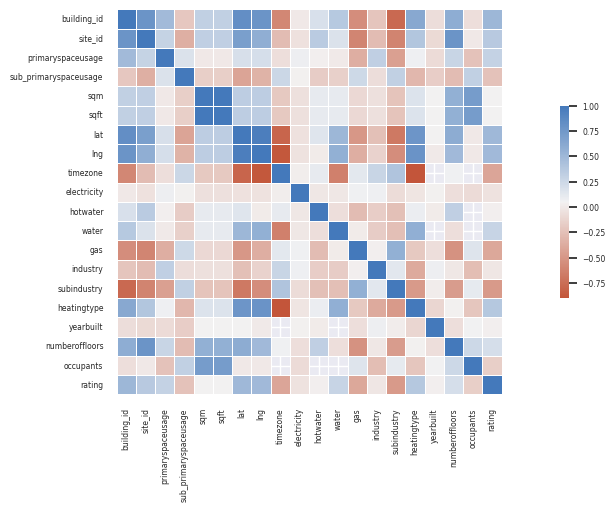

In [18]:
sns.set(font_scale=0.5, rc={'figure.figsize':(15,5)})
cmap = sns.diverging_palette(20, 250, as_cmap=True)
sns.heatmap(metadata.corr(),  cmap=cmap, #vmax=.0, center=0.5,
            square=True, linewidths=.5, cbar_kws={"shrink": .5})

We can see that (as expected) lat and lng have a high correlation with each other as well as with the timezone. Why is that? What should we do (or not do about it)?

Logically we can derive that these columns tell us the same information in different ways. Of course, different site_ids will have different lat and lon, but same site_id will have the same lat and lon. The best practice is usually removing columns that do not communicate any additional value to us. Which columns could we remove without losing too much information?

In [19]:
metadata["heatingtype"].value_counts()

heatingtype
5     172
12     36
7      24
2       5
4       3
11      2
10      2
3       2
8       1
9       1
0       1
1       1
6       1
Name: count, dtype: int64

In [20]:
metadata.loc[metadata["timezone"]!=1]["heatingtype"].unique()

array([12])

### Task III

In [21]:
columns_to_drop = [] # Your code here


In [22]:
columns_to_drop = ["lat", "lng", "sqft"]

In [23]:
metadata = metadata.drop(columns=columns_to_drop)

#### Correlation with the target

Don't forget that now we are only looking at buildings' metadata! Our goal is to predict how these buildings would behave in terms of energy consumption. Let's look at the correlation in the train dataset:

<Axes: >

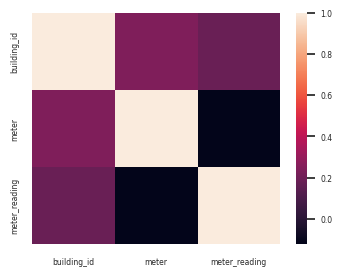

In [24]:
sns.set(font_scale=0.5, rc={'figure.figsize':(4,3)})
sns.heatmap(train[["building_id", "meter", "meter_reading"]].corr())

Ok, so our meter type doesn't correlate with our target value. Building Id on the other hand does have some correlation with the target

<Axes: >

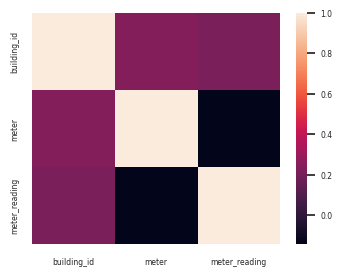

In [25]:
sns.heatmap(train[["building_id", "meter", "meter_reading"]].groupby(["building_id", "meter"], as_index=False).mean().corr())

<Axes: >

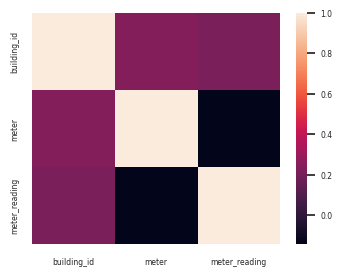

In [26]:
sns.heatmap(train[["building_id", "meter", "meter_reading"]].groupby(["building_id", "meter"], as_index=False).sum().corr())

### Comparing two dataframes

In [27]:
full_df = train.merge(metadata, on='building_id', how='left')
full_df.head()

,building_id,day,meter,meter_reading,site_id,primaryspaceusage,sub_primaryspaceusage,sqm,timezone,electricity,hotwater,water,gas,industry,subindustry,heatingtype,yearbuilt,numberoffloors,occupants,rating
0,2,2016-02-02,595,102.6,0,1,4,811.0,1,0,0,0,1,1,9,5,1976.0,1.0,NaN,6
1,2,2016-02-02,207,0.3,0,1,4,811.0,1,0,0,0,1,1,9,5,1976.0,1.0,NaN,6
2,2,2016-02-03,595,88.8,0,1,4,811.0,1,0,0,0,1,1,9,5,1976.0,1.0,NaN,6
3,2,2016-02-03,207,0.1,0,1,4,811.0,1,0,0,0,1,1,9,5,1976.0,1.0,NaN,6
4,2,2016-02-04,595,76.3,0,1,4,811.0,1,0,0,0,1,1,9,5,1976.0,1.0,NaN,6


In [28]:
full_df["meter_reading"].shape

(266266,)

#### Task IV - check correlation between the columns and the target

<Axes: >

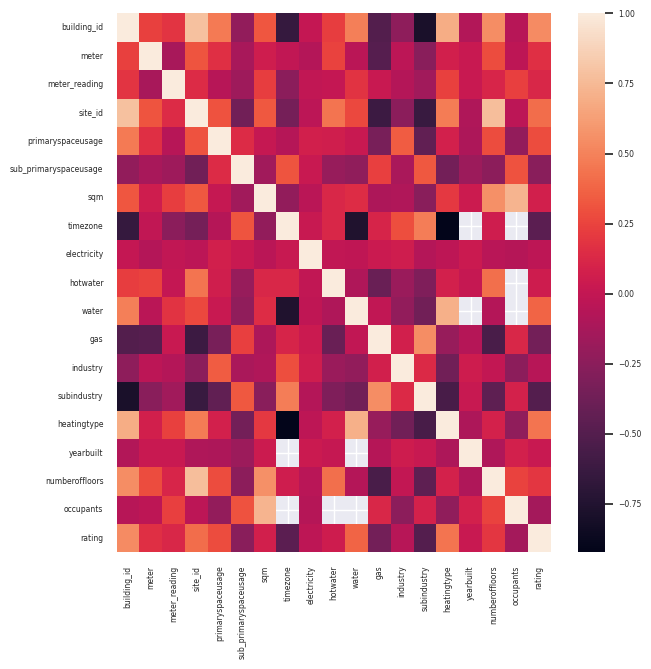

In [29]:
sns.set(font_scale=0.5, rc={'figure.figsize':(7,7)})
sns.heatmap(full_df.drop(columns=[ "day"]).corr())

Can you see any patterns in this diagram? What information does it provide regarding the given buildings?

Answer:
* site_id correlates with the number of floors, which means that most of the buildings on one site are similar in their height
* heatingtype correlates with site_id and timezone; we have already noticed that one timezone is characterized of one particular heating type; now we can see that it even correlates with gas and water;
* features that have strongest correlation with the target value are occupants, heatingtype, sqm



### Missing values

There are several reasons for having missing values, some of which are:
* equipment failure (e.g. GPS sensors)
* unfilled optional values (e.g. "anything else you would like to add" - question in a survey)
* data was not originally collected (two datasets were merged, one had "year" records and another one didn't)
* and so on

For us it is important to understand why the values might be missing, as it gives us an understanding of how to treat them. There are several strategies:
* Remove rows or columns with missing values (used when there are many missing values along one axis)
* Assign an arbitrary value, like 18783 or 0 as to say "this value is missing" (used when we can not remove records from the db)
* Fill in missing values using some logic (e.g. assuming the number of occupants in a building based on similar buildings around or getting the year it was built in from another data source).
    

How to find missing values:

[Click>>](https://www.google.com/search?q=pandas+find+missing+values&oq=pandas+find+missing+values&gs_lcrp=EgZjaHJvbWUyBggAEEUYOTIGCAEQLhhA0gEINTg2N2owajGoAgCwAgA&sourceid=chrome&ie=UTF-8)

One of the methods is to check for each cell whether it is a NaN value and look at the values count that we are already familiar with:

In [30]:
metadata.isna()

,building_id,site_id,primaryspaceusage,sub_primaryspaceusage,sqm,timezone,electricity,hotwater,water,gas,industry,subindustry,heatingtype,yearbuilt,numberoffloors,occupants,rating
136,False,False,False,False,False,False,False,False,False,False,False,False,False,True,False,True,False
137,False,False,False,False,False,False,False,False,False,False,False,False,False,True,False,True,False
138,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,True,False
139,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,True,False
140,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,True,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1631,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,True,False
1632,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,True,False
1633,False,False,False,False,False,False,False,False,False,False,False,False,False,True,False,True,False
1634,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,True,False


In [31]:
for c in metadata.columns:
    if len(metadata[c].isna().unique())>1:
        print(metadata[c].isna().value_counts())
        print("\n")

yearbuilt
False    199
True      52
Name: count, dtype: int64


numberoffloors
False    224
True      27
Name: count, dtype: int64


occupants
True     138
False    113
Name: count, dtype: int64




#### Nearest neighbours

[Algorithm in 94 seconds](https://www.youtube.com/watch?v=zeFt_JCA3b4)

In [32]:
from sklearn.neighbors import KNeighborsRegressor
model = KNeighborsRegressor(n_neighbors=5)
cols_to_drop = ["occupants", "numberoffloors", "yearbuilt"] #, "building_id"]
X = metadata.loc[metadata["occupants"].isna()==False].drop(columns=cols_to_drop)
Y = metadata.loc[metadata["occupants"].isna()==False]["occupants"]
missing_X = metadata.loc[metadata["occupants"].isna()].drop(columns=cols_to_drop)
model.fit(X, Y)

KNeighborsRegressor()

In [33]:
missing_Y = model.predict(missing_X)
missing_Y

array([ 195.8,   18.2, 1156.4,  745.6,  344.8,  359.6, 1019.8,  341.8,
       1156.4, 1082. , 1260.6,  336.6,  194.8, 1256.2,  832. ,  507. ,
       1160.8,  745.6,  344.8,  336.6,  184.4,  294.2,  359.6, 1043.8,
       1043.8,  344.8,  415.4,  745.6,  415.4,  195.8,  415.4,  334.6,
        415.4,  865.6,  344.8,  195.8,  164.6,  164.6,  173.6,  344.8,
         81.4,  390.6,  745.6,  966. ,  745.6,  415.4,  395.8,   99.6,
        195.8,  184.4,  371.4,  239.6,   18.2,  957.2,  425. ,   66.6,
        131. ,  193.2,   37.8,  407.8,   82.4,  344.8,   71.4,  195.8,
         82.4,   71.8,  425. ,  160.2,   66.6,  164.6,   71.8,   37.8,
        129.8,  365.6, 1160.8,  216.4,   53.8,  193.2,  205.6,  365.6,
         54.6,  165.4,  129.8,  175. ,   18.2,  351.6,  129.8,   53.8,
         34.8,  376.2,  333.6,  182. ,  307.8,  397.6,  195.8, 1019.8,
         18.2,   71. ,  351.6,   23.4,   59.4,  348.8, 1214.8,   23.4,
        357.4,  359.6, 1160.8,  359.4,  884.4, 1050.2, 1050.2,  857.6,
      

Thinking about how the algorithm works, do you think some columns are more important than the others? Are there any columns that are not important?

In [34]:
model = KNeighborsRegressor(n_neighbors=5)
cols_to_drop = ["occupants", "numberoffloors", "yearbuilt", "building_id"]
X = metadata.loc[metadata["occupants"].isna()==False].drop(columns=cols_to_drop)
Y = metadata.loc[metadata["occupants"].isna()==False]["occupants"]
missing_X = metadata.loc[metadata["occupants"].isna()].drop(columns=cols_to_drop)
model.fit(X, Y)
missing_Y = model.predict(missing_X)
missing_Y

array([ 195.8,   18.2, 1156.4,  756.2,  344.8,  385.6, 1019.8,  397.6,
       1156.4, 1082. , 1260.6,  364.4,  122.2, 1256.2,  832. ,  507. ,
       1160.8,  745.6,  344.8,  364.4,  193.6,  331.4,  366.6, 1043.8,
       1043.8,  344.8,  415.4,  745.6,  415.4,  195.8,  415.4,  334.6,
        415.4, 1019.8,  344.8,  195.8,  164.6,  164.6,  193.2,  344.8,
        142. ,  397.6,  745.6,  966. ,  745.6,  415.4,  363. ,  113.2,
        195.8,  130. ,  346. ,  244.4,   18.2,  957.2,  341.8,   41.6,
        161.4,  193.2,   18.2,  385.6,   81.4,  344.8,   41.6,  195.8,
        106.4,   66.2,  341.8,  122.2,   41.6,  164.6,   85.8,   18.2,
        113.2,  364.4, 1160.8,  193.6,   41.6,  193.2,  295.6,  346. ,
         71.4,   81.4,  113.2,   70. ,   18.2,  351.6,  169. ,   41.6,
         18.2,  363. ,  301.2,  146.2,  378.2,  397.6,  195.8, 1019.8,
         18.2,  142. ,  334.6,   66.2,   85.8,  377.6, 1214.8,   71.4,
        392. ,  385.6, 1160.8,  430.6,  884.4, 1050.2, 1050.2,  857.6,
      

scaling

In [35]:
from sklearn.preprocessing import MinMaxScaler

scaler = MinMaxScaler() 
X_scaled = scaler.fit_transform(X) 
missing_X_scaled = scaler.fit_transform(missing_X) 

model.fit(X_scaled, Y)
missing_Y = model.predict(missing_X_scaled)
missing_Y

array([ 306.8,  306.8,  451. ,  379.2,  306.8,  306.8,  542.4,  216. ,
        451. ,  556.8,  542.4,  306.8,  216. ,  470.6,  451. ,  306.8,
        522.2,  306.8,  306.8,  344.8,  306.8,  306.8,  432. ,  485. ,
        485. ,  485. ,  485. ,  485. ,  489. ,  379.2,  485. ,  432. ,
        379.2,  485. ,  485. ,  485. ,  485. ,  489. ,  355. ,  489. ,
        379.2,  485. ,  485. ,  485. ,  485. ,  485. ,  485. ,  379.2,
        485. ,  379.2,  485. ,  485. ,   69.8,  853. ,  116.6,  159.8,
         64.4,   56.6,  122.4,  135.8,   64.4,  120.4,   29.2,  135.8,
         29.2,   29.2,  116.6,   65.2,  122.4,  148.6,  299.2,  159.8,
        210.8,  340.2, 1275.8,  265. ,  226. ,  393.2,   68.8,  299.2,
         88.2,   88.2,   88.2,   88.2,   88.2,  384.4,  384.4,  377.4,
        295. ,  339.2,  330.6,  299.2,  294. ,  299.2,  289.2,  397. ,
        119.6,  316.6,  306.8,  122.4,   82. ,  340.2,  542.4,  312.2,
        306.8,  306.8, 1465.6,  340.2, 1271.2,  485. ,  561.4,  397. ,
      

In [36]:
missing_X.tail()

,site_id,primaryspaceusage,sub_primaryspaceusage,sqm,timezone,electricity,hotwater,water,gas,industry,subindustry,heatingtype,rating
1631,1,3,11,17193.0,1,0,0,0,0,2,3,2,7
1632,1,3,11,5399.0,1,0,0,0,0,2,3,2,7
1633,1,3,11,1749.0,1,0,0,0,0,2,3,1,7
1634,1,4,12,3489.0,1,0,0,0,0,3,4,6,7
1635,1,10,14,5931.0,1,0,0,0,0,2,5,2,7


In [39]:
label_dict["industry"].inverse_transform([2,3])

array(['Healthcare', 'Hospitality'], dtype=object)

In [40]:
label_dict["subindustry"].inverse_transform([3,4,5])

array(['Hospital', 'Hotel', 'Laboratory'], dtype=object)

In [58]:
full_df.loc[full_df["subindustry"]==8].loc[full_df["occupants"].isna()==False]

,building_id,day,meter,meter_reading,site_id,primaryspaceusage,sub_primaryspaceusage,sqm,timezone,electricity,hotwater,water,gas,industry,subindustry,heatingtype,yearbuilt,numberoffloors,occupants,rating
33124,74,2016-02-02,595,83.800,0,0,20,736.0,1,0,0,0,1,0,8,5,1966.0,1.0,101.0,9
33125,74,2016-02-02,207,319.819,0,0,20,736.0,1,0,0,0,1,0,8,5,1966.0,1.0,101.0,9
33126,74,2016-02-03,595,55.200,0,0,20,736.0,1,0,0,0,1,0,8,5,1966.0,1.0,101.0,9
33127,74,2016-02-03,207,200.327,0,0,20,736.0,1,0,0,0,1,0,8,5,1966.0,1.0,101.0,9
33128,74,2016-02-04,595,84.100,0,0,20,736.0,1,0,0,0,1,0,8,5,1966.0,1.0,101.0,9
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
134402,292,2017-10-28,207,1034.608,0,0,20,8255.0,1,0,0,0,1,0,8,5,1976.0,2.0,1071.0,4
134403,292,2017-10-29,595,466.490,0,0,20,8255.0,1,0,0,0,1,0,8,5,1976.0,2.0,1071.0,4
134404,292,2017-10-29,207,1957.039,0,0,20,8255.0,1,0,0,0,1,0,8,5,1976.0,2.0,1071.0,4
134405,292,2017-10-30,595,1073.830,0,0,20,8255.0,1,0,0,0,1,0,8,5,1976.0,2.0,1071.0,4


Have you noticed anything that doesn't turn with the predicted values?

In [51]:
missing_Y = missing_Y.astype(int)

In [52]:
metadata["occupants"].loc[metadata["occupants"].isna()] = missing_Y

/tmp/ipykernel_602/3437343726.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  metadata["occupants"].loc[metadata["occupants"].isna()] = missing_Y


#### Building year

In [64]:
from sklearn.tree import DecisionTreeRegressor

cols_to_drop = ["numberoffloors", "yearbuilt"]

X = metadata.loc[metadata["yearbuilt"].isna()==False].drop(columns=cols_to_drop)
Y = metadata.loc[metadata["yearbuilt"].isna()==False]["yearbuilt"]
missing_X = metadata.loc[metadata["yearbuilt"].isna()].drop(columns=cols_to_drop)

tree = DecisionTreeRegressor()
tree.fit(X, Y)

DecisionTreeRegressor()

In [69]:
zipped = [(x, i) for i,x in sorted(zip(tree.feature_importances_, X), reverse=True)]
for f,v in zipped:
    print("{:18s}\t\t{:.2f}".format(f, v))

sqm               		0.29
occupants         		0.26
sub_primaryspaceusage		0.11
rating            		0.11
heatingtype       		0.10
site_id           		0.05
industry          		0.03
primaryspaceusage 		0.02
subindustry       		0.02
hotwater          		0.01
gas               		0.00
water             		0.00
timezone          		0.00
electricity       		0.00


In [66]:
cols_to_drop = ["numberoffloors", "yearbuilt", "building_id"]

X = metadata.loc[metadata["yearbuilt"].isna()==False].drop(columns=cols_to_drop)
Y = metadata.loc[metadata["yearbuilt"].isna()==False]["yearbuilt"]
missing_X = metadata.loc[metadata["yearbuilt"].isna()].drop(columns=cols_to_drop)

tree = DecisionTreeRegressor()
tree.fit(X, Y)

DecisionTreeRegressor()

In [231]:
tree.predict(missing_X)

array([1906., 2004., 2006., 1906., 1966., 1906., 1930., 1919., 1919.,
       1960., 1965., 1945., 1915., 1902., 1906., 2000., 2000., 2000.,
       2000., 2000., 2000., 2000., 2000., 2000., 2000., 2000., 2000.,
       2000., 2000., 2000., 2000., 2000., 2000., 2000., 2000., 2000.,
       2000., 2000., 2000., 2000., 2000., 2000., 2000., 2000., 2000.,
       2000., 2000., 2000., 2000., 2000., 2000., 1954.])

#### Task V - Assign predictions 

In [ ]:
metadata["yearbuilt"] # Your code here

In [70]:
# answer
metadata["yearbuilt"].loc[metadata["yearbuilt"].isna()] = tree.predict(missing_X).astype(int)

/tmp/ipykernel_602/2202934034.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  metadata["yearbuilt"].loc[metadata["yearbuilt"].isna()] = tree.predict(missing_X).astype(int)


In [71]:
metadata["yearbuilt"].loc[metadata["yearbuilt"].isna()]

Series([], Name: yearbuilt, dtype: float64)

In [72]:
metadata.head()

,building_id,site_id,primaryspaceusage,sub_primaryspaceusage,sqm,timezone,electricity,hotwater,water,gas,industry,subindustry,heatingtype,yearbuilt,numberoffloors,occupants,rating
136,432,3,0,2,4703.0,1,0,0,0,0,0,2,11,1906.0,5.0,195.0,8
137,416,3,0,2,499.3,1,0,1,0,0,0,2,7,2006.0,4.0,18.0,9
138,436,3,0,2,9061.0,1,0,0,0,0,0,2,7,2005.0,10.0,1156.0,7
139,441,3,0,3,7579.0,1,0,0,0,0,0,2,7,1913.0,5.0,756.0,9
140,442,3,0,3,5295.0,1,0,1,0,0,0,2,7,1953.0,6.0,344.0,8


## Looking closer at the data

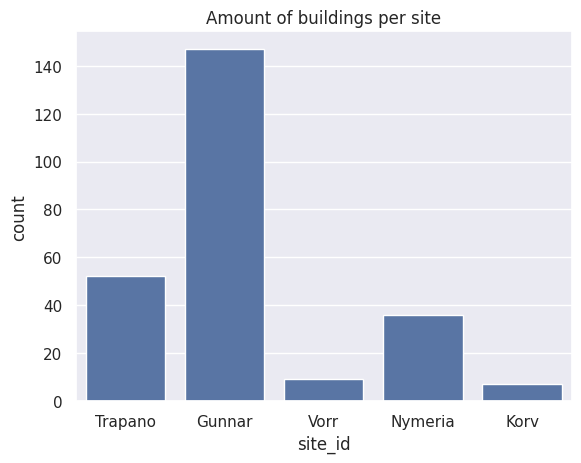

In [26]:
plt.title("Amount of buildings per site")
_ = sns.countplot(metadata, x="site_id")


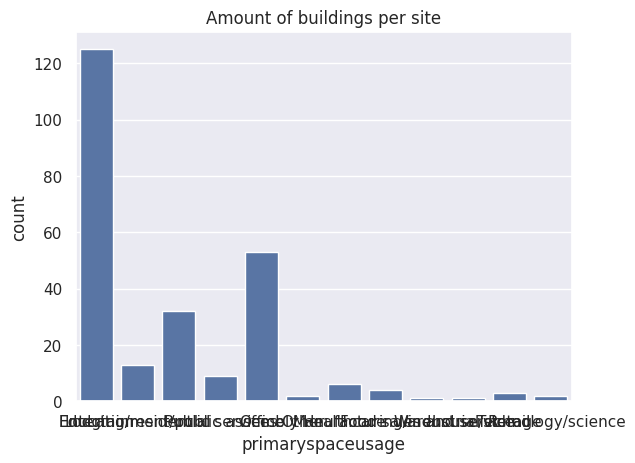

In [27]:
plt.title("Amount of buildings per site")
_ = sns.countplot(metadata, x="primaryspaceusage")


How to fix the font dimensions:

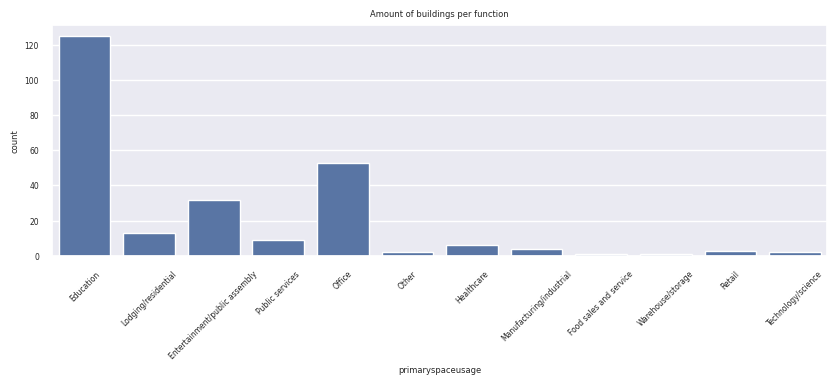

In [44]:
sns.set(font_scale=0.5, rc={'figure.figsize':(10,3)})
plt.title("Amount of buildings per function")
plt.xticks(rotation=45)  # rotate the labels
_ = sns.countplot(metadata, x="primaryspaceusage")


How are buildings distributed across the secondary category?

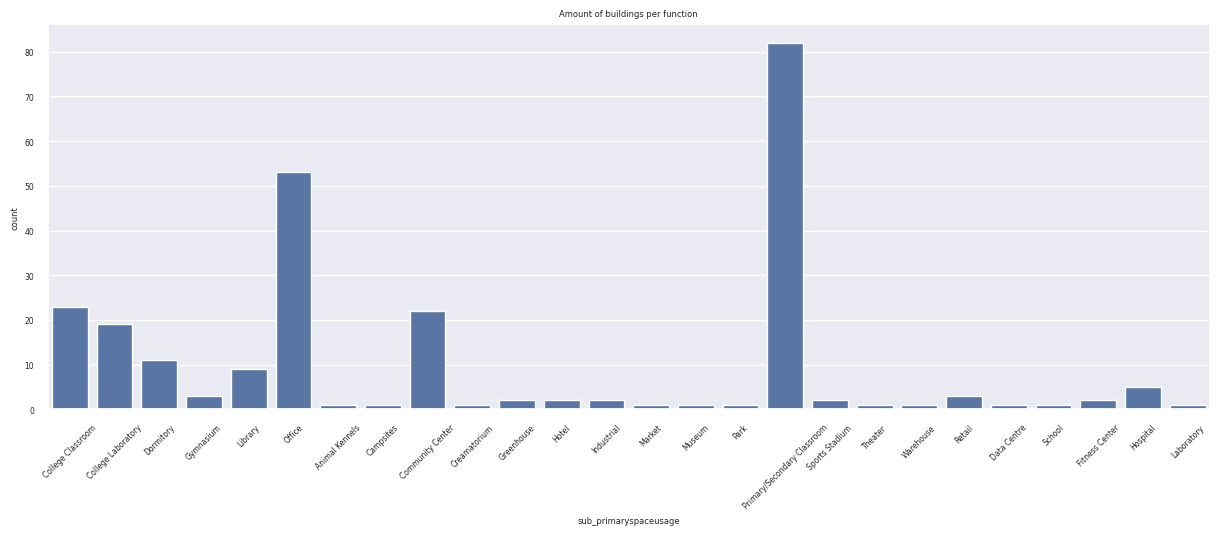

In [42]:
sns.set(font_scale=0.5, rc={'figure.figsize':(15,5)})
plt.title("Amount of buildings per function")
plt.xticks(rotation=45)  # rotate the labels
_ = sns.countplot(metadata, x="sub_primaryspaceusage")

Ok, good, these diagrams would look good in any report. But what do they tell us about the problem? Is there a more meaningful way to visualize building usage?

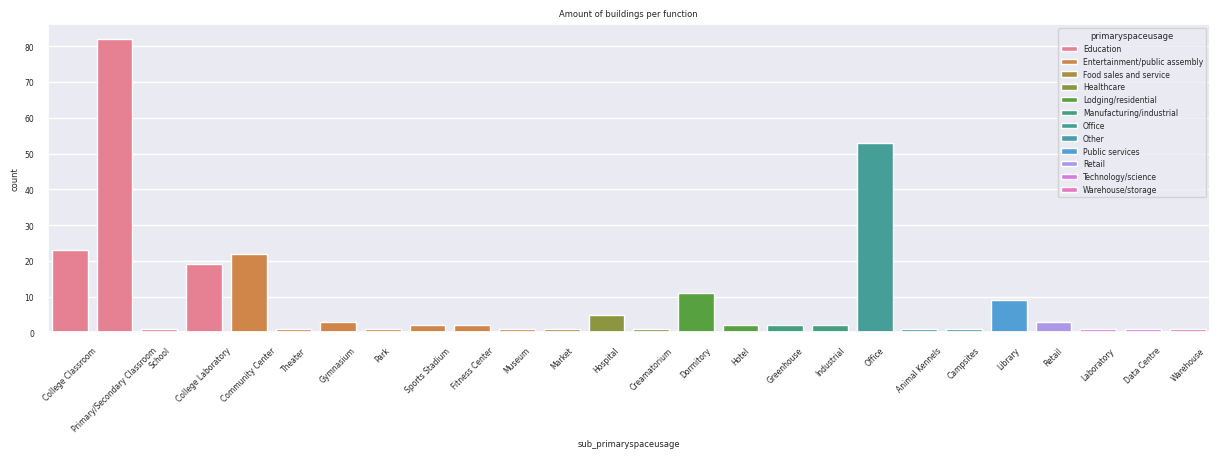

In [40]:

sns.set(font_scale=0.5, rc={'figure.figsize':(15,4)})
plt.title("Amount of buildings per function")
plt.xticks(rotation=45)  # rotate the labels
_ = sns.countplot(metadata.sort_values(by="primaryspaceusage"), x="sub_primaryspaceusage", hue="primaryspaceusage")


This diagram carries more information: now we understand how subcategories are spread across different categories. We know that the largest category ("education") consists mostly of classrooms, while the next largest category ("Office") is not divided into subcategories at all. Entertainment is rather skewed as well: most of the buildings belong to the "Community Center" subcategory.

What does it mean in practice when we predict valeus based on these data?